## 1. Carga de Datos y Configuración del Entorno


In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid", palette="Blues_d")
pd.set_option("display.float_format", "{:,.2f}".format)
print("Librerías listas")

Librerías listas


In [102]:
ruta_csv = os.path.join(path, "ai_model_price_history.csv")
datos = pd.read_csv(ruta_csv)

print("Datos cargados correctamente.")

Datos cargados correctamente.


In [103]:
ruta_csv = os.path.join(path, "ai_model_price_history.csv")
datos = pd.read_csv(ruta_csv)

## 2. Análisis Exploratorio de Datos (EDA)

In [104]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167787 entries, 0 to 167786
Data columns (total 9 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   week_start                  167787 non-null  object 
 1   model_id                    167787 non-null  object 
 2   model_name                  167745 non-null  object 
 3   developer                   167787 non-null  object 
 4   provider                    167787 non-null  object 
 5   mode                        167787 non-null  object 
 6   input_price_per_1m_tokens   166742 non-null  float64
 7   output_price_per_1m_tokens  166643 non-null  float64
 8   max_input_tokens            154426 non-null  float64
dtypes: float64(3), object(6)
memory usage: 11.5+ MB


In [105]:
print("Valores nulos por columna: ")
print(datos.isna().sum())
print("\nFilas duplicados", datos.duplicated().sum())

Valores nulos por columna: 
week_start                        0
model_id                          0
model_name                       42
developer                         0
provider                          0
mode                              0
input_price_per_1m_tokens      1045
output_price_per_1m_tokens     1144
max_input_tokens              13361
dtype: int64

Filas duplicados 0


In [106]:
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
input_price_per_1m_tokens,"166,742.00",2.97,11.81,0.00,0.13,0.50,2.00,250.00
output_price_per_1m_tokens,"166,643.00",8.90,29.11,0.00,0.24,1.20,7.00,"1,000.00"
max_input_tokens,"154,426.00","236,363.41","520,189.43",77.00,"30,720.00","128,000.00","200,000.00","10,485,760.00"


In [107]:
datos["output_price_per_1m_tokens"].value_counts()

,count
output_price_per_1m_tokens,
0.00,18433
15.00,8293
0.20,6888
10.00,6308
0.60,5448
...,...
0.04,1
0.14,1
0.10,1


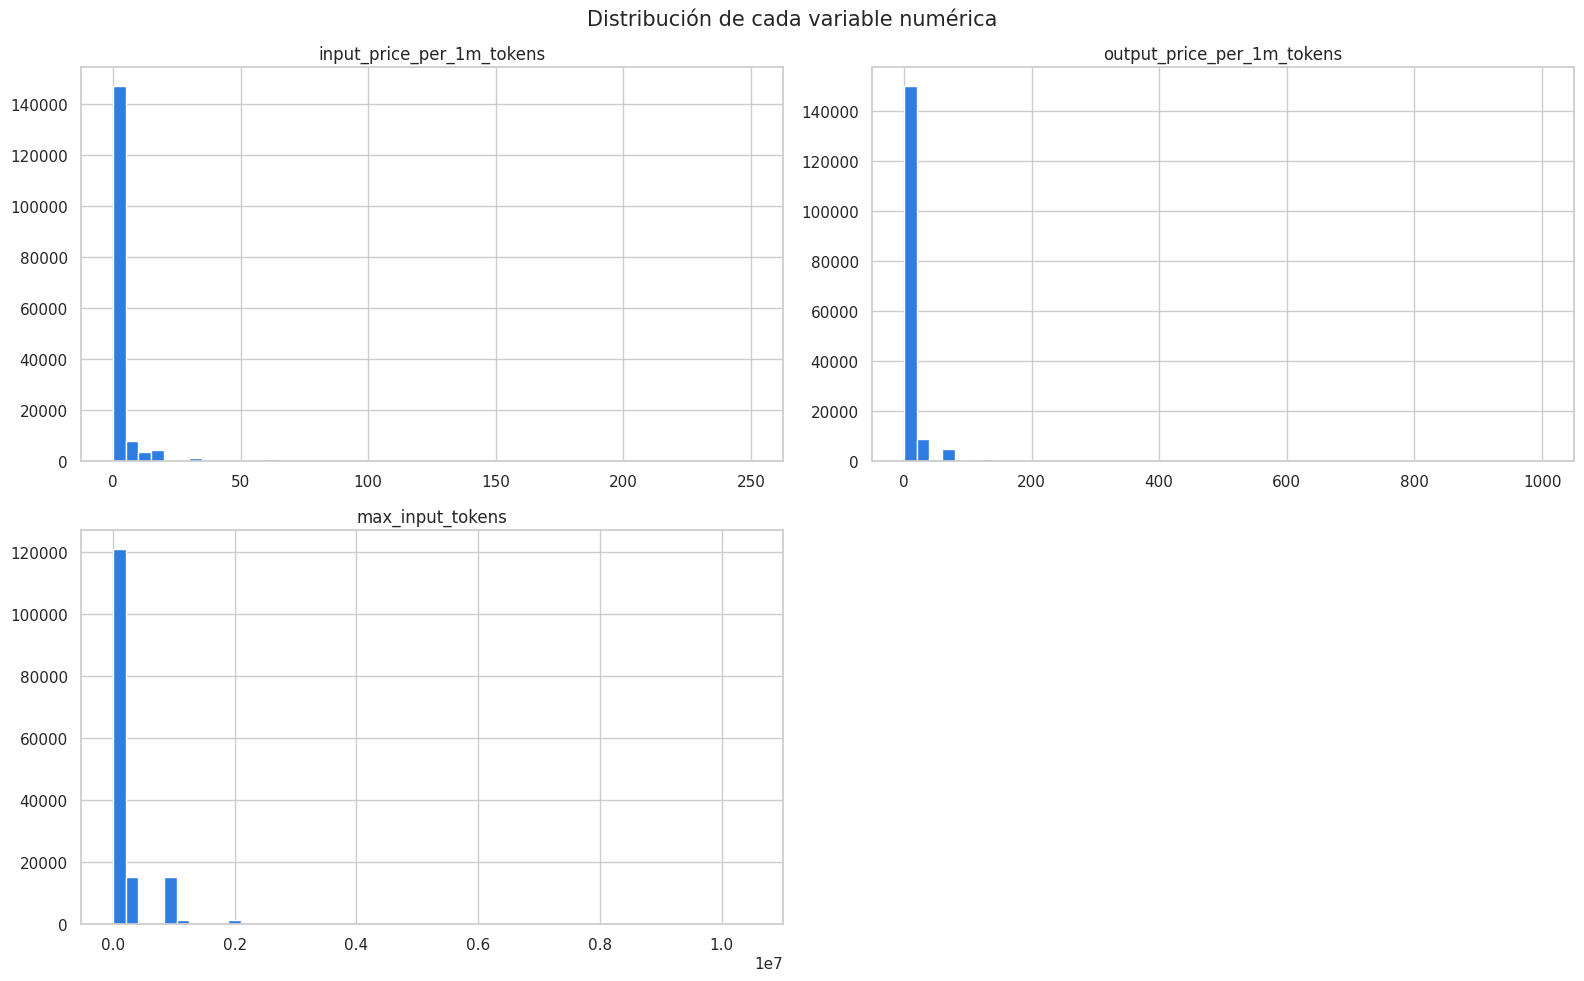

In [108]:
datos.hist(bins=50, figsize=(16,10), color="#2F7DE1")
plt.suptitle("Distribución de cada variable numérica", fontsize=15)
plt.tight_layout()
plt.show()

In [109]:
q1 = datos["output_price_per_1m_tokens"].quantile(0.25)
q3 = datos["output_price_per_1m_tokens"].quantile(0.75)
iqr = q3 - q1
limite_outliers = q3 + 1.5 * iqr

cantidad_outliers = (datos["output_price_per_1m_tokens"] > limite_outliers).sum()
print(f"Modelos con precios atípicos superiores a ${limite_outliers:.2f} USD: {cantidad_outliers}")

Modelos con precios atípicos superiores a $17.14 USD: 17559


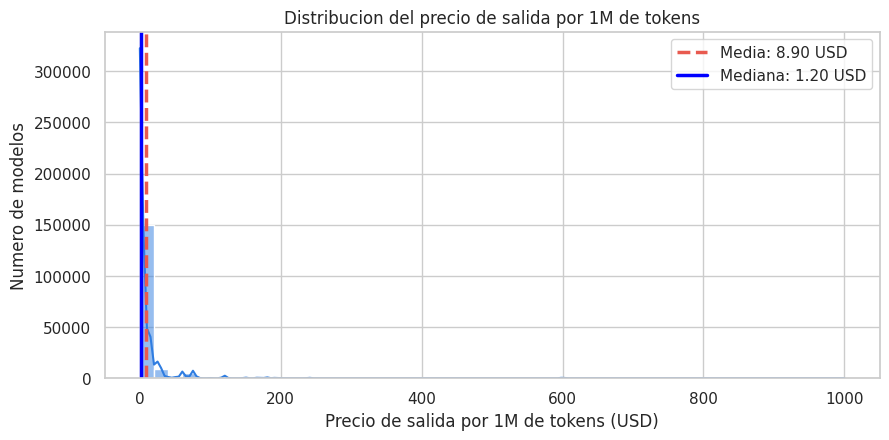

Modelos con precios atipicos superiores a $17.14 USD: 17559


In [110]:
media = datos["output_price_per_1m_tokens"].mean()
mediana = datos["output_price_per_1m_tokens"].median()

plt.figure(figsize=(10, 4.5))
sns.histplot(datos["output_price_per_1m_tokens"], bins=50, kde=True, color="#2F7DE1")
plt.axvline(media, color="#E85A4F", linestyle="--", linewidth=2.5, label=f"Media: {media:,.2f} USD")
plt.axvline(mediana, color="#0000FF", linewidth=2.5, label=f"Mediana: {mediana:,.2f} USD")
plt.title("Distribucion del precio de salida por 1M de tokens")
plt.xlabel("Precio de salida por 1M de tokens (USD)")
plt.ylabel("Numero de modelos")
plt.legend()
plt.show()

print("Modelos con precios atipicos superiores a $17.14 USD:", (datos["output_price_per_1m_tokens"] >= limite_outliers).sum())

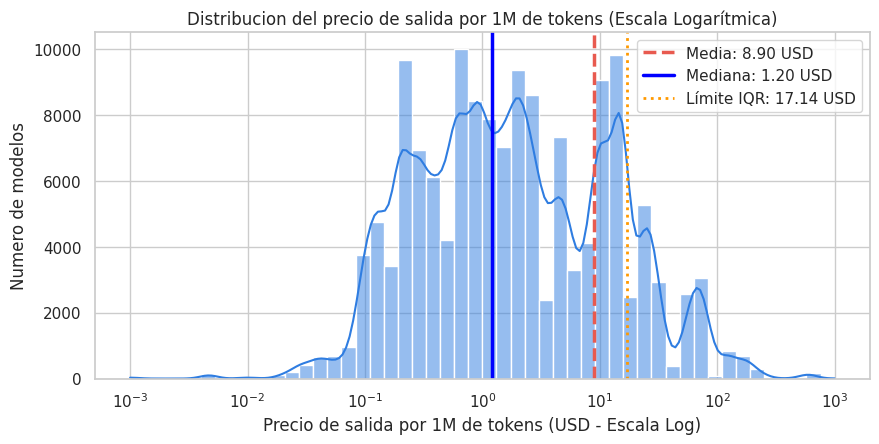

Modelos con precios atipicos superiores a $17.14 USD: 17559


In [111]:
media = datos["output_price_per_1m_tokens"].mean()
mediana = datos["output_price_per_1m_tokens"].median()

datos_pos = datos[datos["output_price_per_1m_tokens"] > 0]

plt.figure(figsize=(10, 4.5))
sns.histplot(
    datos_pos["output_price_per_1m_tokens"],
    bins=50,
    kde=True,
    log_scale=True,
    color="#2F7DE1"
)
plt.axvline(media, color="#E85A4F", linestyle="--", linewidth=2.5, label=f"Media: {media:,.2f} USD")
plt.axvline(mediana, color="#0000FF", linewidth=2.5, label=f"Mediana: {mediana:,.2f} USD")
plt.axvline(limite_outliers, color="#FF9900", linestyle=":", linewidth=2, label=f"Límite IQR: {limite_outliers:,.2f} USD")

plt.title("Distribucion del precio de salida por 1M de tokens (Escala Logarítmica)")
plt.xlabel("Precio de salida por 1M de tokens (USD - Escala Log)")
plt.ylabel("Numero de modelos")
plt.legend()
plt.show()

print(f"Modelos con precios atipicos superiores a ${limite_outliers:.2f} USD:", (datos["output_price_per_1m_tokens"] >= limite_outliers).sum())

En este dataset no hay censura de datos, sino variabilidad extrema de mercado: el 75% de las APIs cobra menos de $7 USD, pero existen 17,559 observaciones que superan los $17.14 USD (llegando hasta $1,000 USD). Este umbral fundamenta la necesidad de aplicar transformaciones (como escala logarítmica) antes de entrenar modelos de regresión o aprendizaje automático.

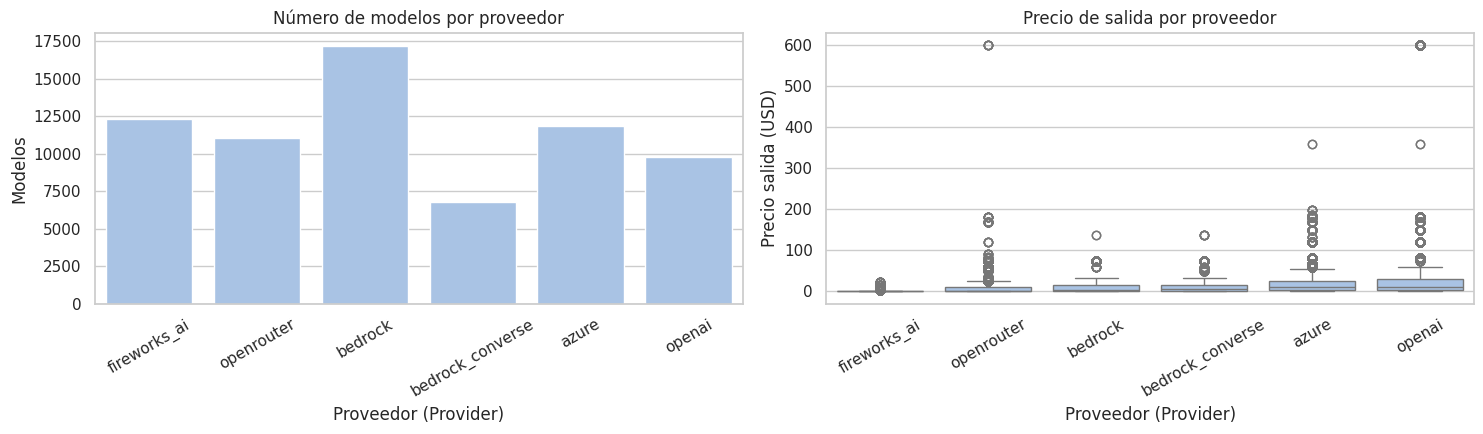

,count,median,mean
provider,,,
azure,11838,10.00,22.22
bedrock,17196,2.40,8.58
bedrock_converse,6761,5.00,12.61
fireworks_ai,12279,0.50,0.93
openai,9759,10.00,35.53
openrouter,11039,1.90,9.71


In [112]:
top_proveedores = datos["provider"].value_counts().nlargest(6).index
datos_filtrados = datos[datos["provider"].isin(top_proveedores)]

orden = datos_filtrados.groupby("provider")["output_price_per_1m_tokens"].median().sort_values().index

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

sns.countplot(data=datos_filtrados, x="provider", order=orden, color="#9FC2EE", ax=ax[0])
ax[0].set(title="Número de modelos por proveedor", xlabel="Proveedor (Provider)", ylabel="Modelos")
ax[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=datos_filtrados, x="provider", y="output_price_per_1m_tokens", order=orden, color="#9FC2EE", ax=ax[1])
ax[1].set(title="Precio de salida por proveedor", xlabel="Proveedor (Provider)", ylabel="Precio salida (USD)")
ax[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

datos_filtrados.groupby("provider")["output_price_per_1m_tokens"].agg(['count', 'median', 'mean'])

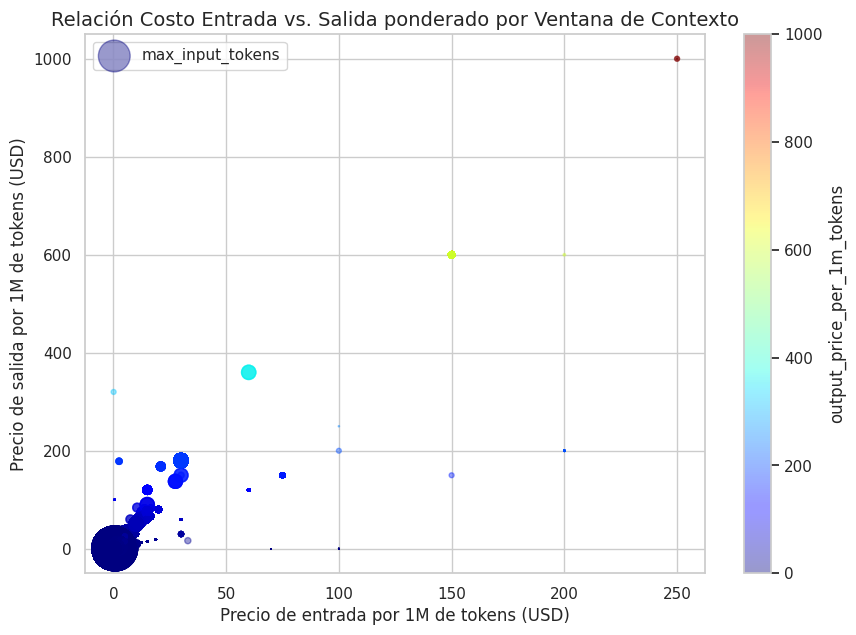

In [113]:
datos_plot = datos.dropna(subset=["input_price_per_1m_tokens", "output_price_per_1m_tokens", "max_input_tokens"])

datos_plot.plot(kind="scatter", x="input_price_per_1m_tokens", y="output_price_per_1m_tokens", alpha=0.4,
    s=datos_plot["max_input_tokens"] / 10000, label="max_input_tokens", figsize=(10, 7),
    c="output_price_per_1m_tokens", cmap=plt.get_cmap("jet"), colorbar=True,
)

plt.legend()
plt.ylabel("Precio de salida por 1M de tokens (USD)")
plt.xlabel("Precio de entrada por 1M de tokens (USD)")
plt.title("Relación Costo Entrada vs. Salida ponderado por Ventana de Contexto", fontsize=14)
plt.show()

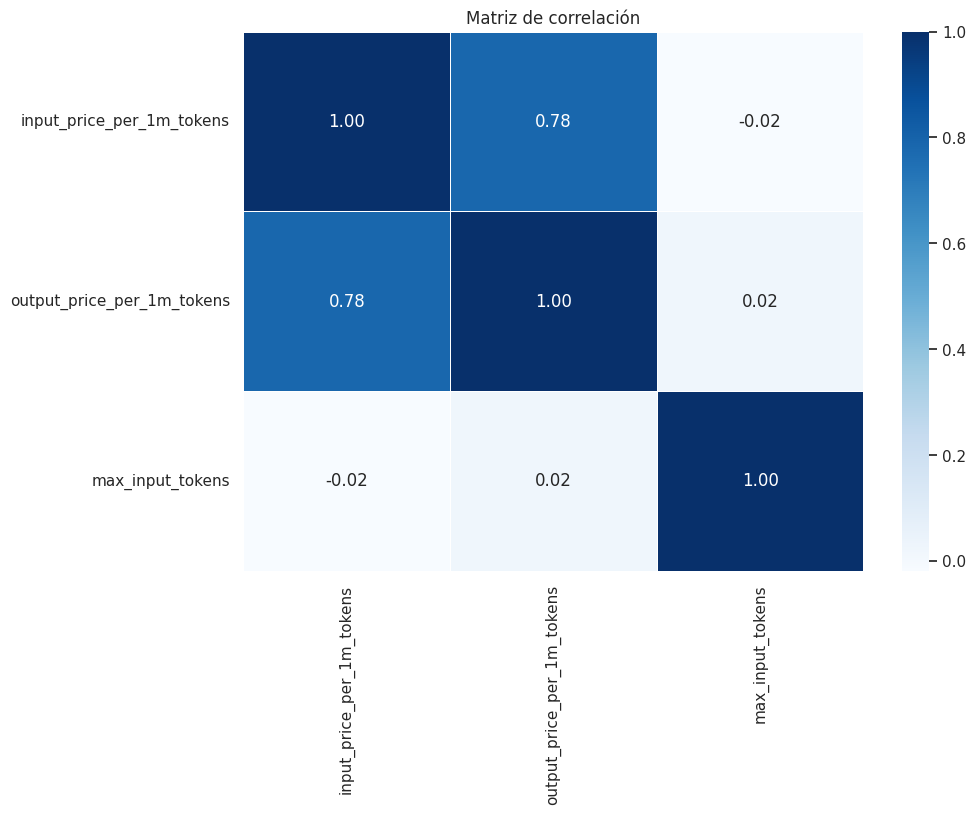

,output_price_per_1m_tokens
output_price_per_1m_tokens,1.00
input_price_per_1m_tokens,0.78
max_input_tokens,0.02


In [114]:
correlacion = datos.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("Matriz de correlación")
plt.show()

correlacion["output_price_per_1m_tokens"].sort_values(ascending=False)

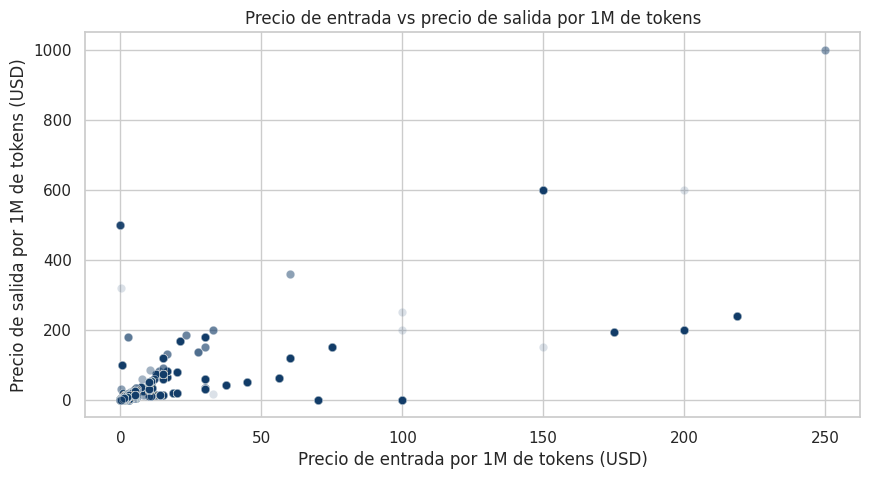

In [115]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=datos,
    x="input_price_per_1m_tokens",
    y="output_price_per_1m_tokens",
    alpha=0.15,
    color="#123C68",
)
plt.title("Precio de entrada vs precio de salida por 1M de tokens")
plt.xlabel("Precio de entrada por 1M de tokens (USD)")
plt.ylabel("Precio de salida por 1M de tokens (USD)")
plt.show()

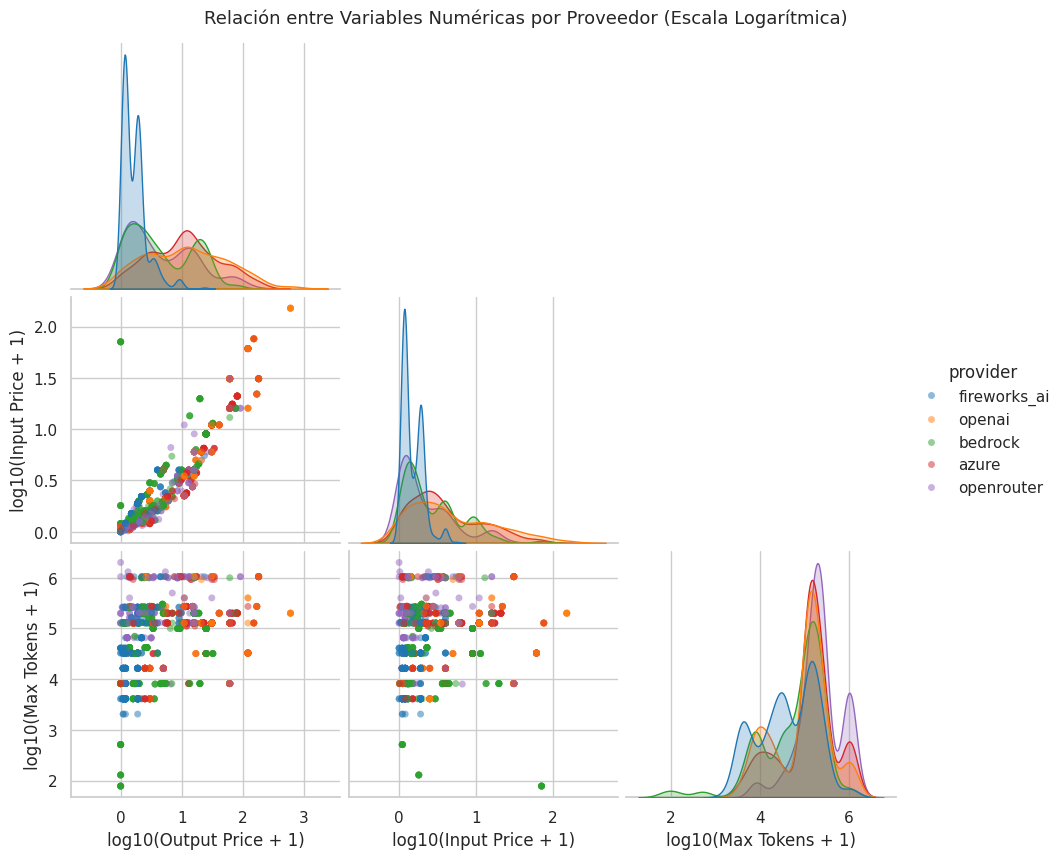

In [116]:
import numpy as np

top_providers = datos["provider"].value_counts().nlargest(5).index
datos_sub = datos[datos["provider"].isin(top_providers)].dropna(
    subset=["output_price_per_1m_tokens", "input_price_per_1m_tokens", "max_input_tokens"]
).copy()

datos_sub["log_output_price"] = np.log10(datos_sub["output_price_per_1m_tokens"] + 1)
datos_sub["log_input_price"] = np.log10(datos_sub["input_price_per_1m_tokens"] + 1)
datos_sub["log_max_tokens"] = np.log10(datos_sub["max_input_tokens"] + 1)

muestra = datos_sub.sample(min(2000, len(datos_sub)), random_state=42)

g = sns.pairplot(
    muestra,
    vars=['log_output_price', 'log_input_price', 'log_max_tokens'],
    hue='provider',
    palette='tab10',
    plot_kws={'alpha': 0.5, 's': 25, 'edgecolor': 'none'},
    diag_kws={'fill': True, 'common_norm': False},
    corner=True,
    height=2.8,
    aspect=1.1
)

g.axes[1, 0].set_ylabel("log10(Input Price + 1)")
g.axes[2, 0].set_ylabel("log10(Max Tokens + 1)")
g.axes[2, 0].set_xlabel("log10(Output Price + 1)")
g.axes[2, 1].set_xlabel("log10(Input Price + 1)")
g.axes[2, 2].set_xlabel("log10(Max Tokens + 1)")

g.fig.suptitle("Relación entre Variables Numéricas por Proveedor (Escala Logarítmica)", y=1.02, fontsize=13)
plt.show()

In [117]:
limpios = datos.dropna(subset=["output_price_per_1m_tokens", "input_price_per_1m_tokens"]).copy()

mediana_tokens = limpios["max_input_tokens"].median()
limpios["max_input_tokens"] = limpios["max_input_tokens"].fillna(mediana_tokens)

print("Nulos restantes en columnas clave:\n", limpios[["output_price_per_1m_tokens", "input_price_per_1m_tokens", "max_input_tokens"]].isna().sum())

Nulos restantes en columnas clave:
 output_price_per_1m_tokens    0
input_price_per_1m_tokens     0
max_input_tokens              0
dtype: int64


## 3. Limpieza y Preparación de Datos (Preprocesamiento & Feature Engineering)


In [118]:
limpios = datos.copy()
filas_iniciales = len(limpios)
print("Filas iniciales:", filas_iniciales)

Filas iniciales: 167787


In [119]:
limpios["ratio_precio_salida_entrada"] = (
    limpios["output_price_per_1m_tokens"] / (limpios["input_price_per_1m_tokens"] + 1e-6)
)
limpios["costo_contexto_maximo"] = (
    (limpios["max_input_tokens"] * limpios["input_price_per_1m_tokens"]) / 1_000_000
)
limpios["diferencia_precio_tokens"] = (
    limpios["output_price_per_1m_tokens"] - limpios["input_price_per_1m_tokens"]
)

nuevas = ["ratio_precio_salida_entrada", "costo_contexto_maximo", "diferencia_precio_tokens"]
limpios[nuevas].describe().T

,count,mean,std,min,25%,50%,75%,max
ratio_precio_salida_entrada,"166,445.00","52,357.11","4,902,931.51",0.00,1.00,3.00,4.00,"500,000,000.00"
costo_contexto_maximo,"153,551.00",0.52,2.00,0.00,0.00,0.05,0.31,63.00
diferencia_precio_tokens,"166,445.00",5.92,21.16,-100.00,0.00,0.48,4.00,750.00


In [120]:
limpios = limpios[limpios["output_price_per_1m_tokens"] <= limite_outliers]
print("Filas después de quitar valores atípicos:", len(limpios))

Filas después de quitar valores atípicos: 149084


In [121]:
print(limpios["mode"].value_counts())

limpios = limpios[limpios["mode"] != "responses"].copy()
print("Filas después de quitar responses:", len(limpios))

mode
chat          132229
embedding       9387
completion      6023
responses       1445
Name: count, dtype: int64
Filas después de quitar responses: 147639


In [122]:
limpios["ratio_precio_salida_entrada"] = (
    limpios["output_price_per_1m_tokens"] / (limpios["input_price_per_1m_tokens"] + 1e-6)
)
limpios["costo_contexto_maximo"] = (
    (limpios["max_input_tokens"] * limpios["input_price_per_1m_tokens"]) / 1_000_000
)
limpios["diferencia_precio_tokens"] = (
    limpios["output_price_per_1m_tokens"] - limpios["input_price_per_1m_tokens"]
)

nuevas = ["ratio_precio_salida_entrada", "costo_contexto_maximo", "diferencia_precio_tokens"]
limpios[nuevas].describe().T

,count,mean,std,min,25%,50%,75%,max
ratio_precio_salida_entrada,"147,441.00","4,845.90","102,743.70",0.00,1.00,2.86,4.00,"2,800,000.00"
costo_contexto_maximo,"136,435.00",0.22,0.61,0.00,0.00,0.03,0.16,10.49
diferencia_precio_tokens,"147,441.00",1.88,4.51,-100.00,0.00,0.30,2.00,13.75


In [123]:
limpios[nuevas] = limpios[nuevas].replace([np.inf, -np.inf], np.nan).fillna(0)

for col in nuevas:
    p1, p99 = np.percentile(limpios[col], [1, 99])
    limpios[col] = np.clip(limpios[col], p1, p99)

limpios[nuevas].describe().T

,count,mean,std,min,25%,50%,75%,max
ratio_precio_salida_entrada,"147,639.00",2.76,2.19,0.00,1.00,2.83,4.00,10.00
costo_contexto_maximo,"147,639.00",0.19,0.47,0.00,0.00,0.02,0.15,3.00
diferencia_precio_tokens,"147,639.00",1.98,3.41,-0.18,0.00,0.30,2.00,12.00


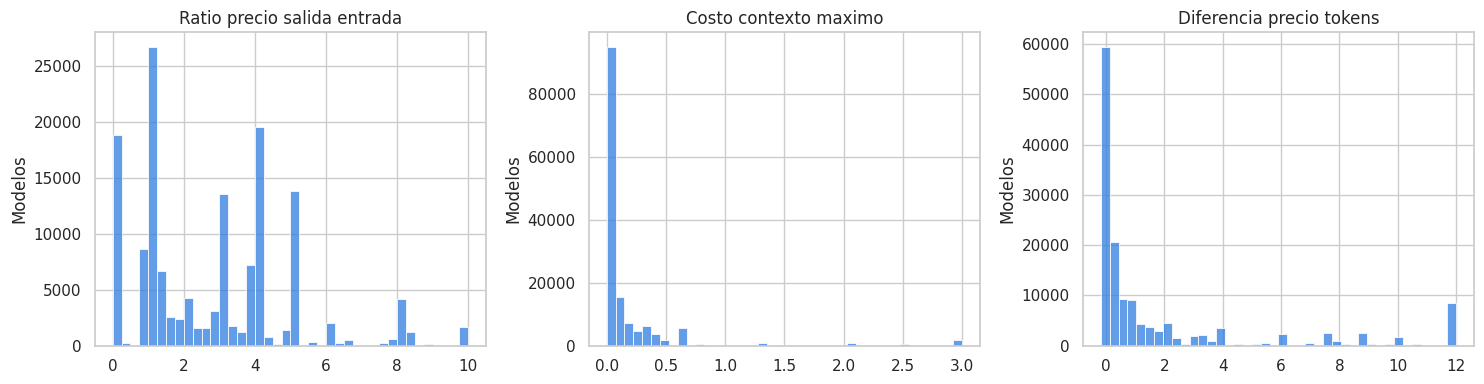

,output_price_per_1m_tokens
ratio_precio_salida_entrada,0.47
costo_contexto_maximo,0.57
diferencia_precio_tokens,0.96
output_price_per_1m_tokens,1.00


In [124]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(nuevas):
    sns.histplot(limpios[col], bins=40, color="#2F7DE1", ax=ax[i])
    ax[i].set(
        title=col.replace("_", " ").capitalize(),
        xlabel="",
        ylabel="Modelos",
    )
plt.tight_layout()
plt.show()

limpios[nuevas + ["output_price_per_1m_tokens"]].corr()[
    "output_price_per_1m_tokens"
]

In [125]:
antes = limpios.memory_usage(deep=True).sum() / 1e6
limpios["provider"] = limpios["provider"].astype("category")
limpios["mode"] = limpios["mode"].astype("category")
despues = limpios.memory_usage(deep=True).sum() / 1e6
print("Memoria: ", antes, "MB -->", despues, "MB")

Memoria:  64.093937 MB --> 47.758624 MB


In [126]:
modelo_datos = pd.get_dummies(limpios, columns=["provider", "mode"], drop_first=True, dtype=int)
modelo_datos.filter(regex="^(provider|mode)_").head()

,provider_aihubmix,provider_amazon_nova,provider_anthropic,provider_anyscale,provider_azure,provider_azure_ai,provider_azure_text,provider_baseten,provider_bedrock,provider_bedrock_converse,...,provider_vertex_ai-zai_models,provider_volcengine,provider_voyage,provider_wandb,provider_watsonx,provider_xai,provider_xiaomi_mimo,provider_zai,mode_completion,mode_embedding
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [127]:
filas_iniciales = len(datos)

resumen = pd.DataFrame({
    "Paso": [
        "Datos originales",
        "Nulos rellenados (max_input_tokens)",
        f"Sin precios atípicos (> ${limite_outliers:.2f} USD)",
        "Sin categoría responses"
    ],
    "Filas": [
        filas_iniciales,
        filas_iniciales,
        filas_iniciales - (datos["output_price_per_1m_tokens"] > limite_outliers).sum(),
        len(limpios)
    ],
})
resumen

,Paso,Filas
0,Datos originales,167787
1,Nulos rellenados (max_input_tokens),167787
2,Sin precios atípicos (> $17.14 USD),150228
3,Sin categoría responses,147639


## 4. Modelado y Evaluación

In [136]:
from sklearn.model_selection import train_test_split
import numpy as np

modelo_datos_limpio = modelo_datos.replace([np.inf, -np.inf], np.nan).fillna(0)

y = modelo_datos_limpio["output_price_per_1m_tokens"]
x = modelo_datos_limpio.drop(columns=["output_price_per_1m_tokens"]).select_dtypes(include=[np.number, bool])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Entrenamiento:", x_train.shape, "| Prueba:", x_test.shape)


Entrenamiento: (118111, 108) | Prueba: (29528, 108)


In [137]:
# Modelo de regresión lineal
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

lineal = LinearRegression()
lineal.fit(x_train, y_train)
pred_lineal = lineal.predict(x_test)

mae_lineal = mean_absolute_error(y_test, pred_lineal)
r2_lineal = r2_score(y_test, pred_lineal)

print(f"Regresión lineal -> MAE: ${mae_lineal:.4f} USD | R2: {r2_lineal:.4f}")


Regresión lineal -> MAE: $0.4634 USD | R2: 0.9501


In [138]:
# Modelo Random Forest
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
pred_rf = rf.predict(x_test)

mae_rf = mean_absolute_error(y_test, pred_rf)
r2_rf = r2_score(y_test, pred_rf)

print(f"Random Forest -> MAE: ${mae_rf:.4f} USD | R2: {r2_rf:.4f}")


Random Forest -> MAE: $0.0002 USD | R2: 1.0000
